In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import os
import yaml
import time
from datetime import datetime, timedelta
import glob
from pathlib import Path

class ReservoirDataScraper:
    def __init__(self, config_path="/content/drive/MyDrive/cos_it_flows/Historical/input/Raw data/Reservoir_data/TN_RES/YML/TN_res.yml"):
        """Initialize the scraper with configuration from YAML file."""
        self.config = self.load_config(config_path)
        self.download_config = self.config['downloading']
        self.output_dir = self.download_config['output']['directory']
        self.setup_output_directory()

    def load_config(self, config_path):
        """Load configuration from YAML file."""
        try:
            with open(config_path, 'r') as file:
                return yaml.safe_load(file)
        except FileNotFoundError:
            print(f"Config file {config_path} not found. Using default configuration.")
            return self.get_default_config()
        except yaml.YAMLError as e:
            print(f"Error parsing config file: {e}")
            return self.get_default_config()

    def get_default_config(self):
        """Return default configuration if YAML file is not found."""
        return {
            'downloading': {
                'output': {
                    'directory': "/content/drive/MyDrive/Data/TN_Res",
                    'create_if_not_exists': True
                },
                'scraping': {
                    'base_url': "http://tnagriculture.in/ARS/home/reservoir/",
                    'date_format': "%Y-%m-%d"
                },
                'data': {
                    'max_columns': 9,
                    'remove_duplicates': True,
                    'save_header': False,
                    'save_index': False
                },
                'fallback_dates': {
                    'start_date': "2021-05-05"
                },
                'requests': {
                    'timeout': 30,
                    'retry_attempts': 3,
                    'retry_delay': 2
                },
                'logging': {
                    'enable_debug': True,
                    'show_progress': True
                }
            }
        }

    def setup_output_directory(self):
        """Create output directory if it doesn't exist."""
        if self.download_config['output']['create_if_not_exists']:
            os.makedirs(self.output_dir, exist_ok=True)
            if self.download_config['logging']['enable_debug']:
                print(f"Output directory set up: {self.output_dir}")

    def get_last_downloaded_date(self):
        """Find the last downloaded date from existing CSV files."""
        csv_files = glob.glob(os.path.join(self.output_dir, "*.csv"))

        if not csv_files:
            if self.download_config['logging']['enable_debug']:
                print("No existing CSV files found. Starting from fallback start date.")
            return datetime.strptime(self.download_config['fallback_dates']['start_date'], "%Y-%m-%d")

        # Extract dates from filenames and find the latest
        dates = []
        for file_path in csv_files:
            filename = os.path.basename(file_path)
            date_str = filename.replace('.csv', '')
            try:
                date_obj = datetime.strptime(date_str, "%Y-%m-%d")
                dates.append(date_obj)
            except ValueError:
                # Skip files that don't match the date format
                continue

        if dates:
            last_date = max(dates)
            next_date = last_date + timedelta(days=1)
            if self.download_config['logging']['enable_debug']:
                print(f"Last downloaded date: {last_date.strftime('%Y-%m-%d')}")
                print(f"Starting from: {next_date.strftime('%Y-%m-%d')}")
            return next_date
        else:
            if self.download_config['logging']['enable_debug']:
                print("No valid date files found. Starting from fallback start date.")
            return datetime.strptime(self.download_config['fallback_dates']['start_date'], "%Y-%m-%d")

    def date_range(self, start_date, end_date):
        """Generate date range from start_date to end_date."""
        for n in range(int((end_date - start_date).days) + 1):
            yield start_date + timedelta(n)

    def download_data_for_date(self, date_obj):
        """Download and save data for a specific date."""
        date_str = date_obj.strftime(self.download_config['scraping']['date_format'])
        url = f"{self.download_config['scraping']['base_url']}{date_str}"

        if self.download_config['logging']['enable_debug']:
            print(f"Attempting to download data for date: {date_str}...")

        # Retry mechanism
        for attempt in range(self.download_config['requests']['retry_attempts']):
            try:
                webpage = requests.get(url, timeout=self.download_config['requests']['timeout'])

                if webpage.status_code == 200:
                    if self.download_config['logging']['enable_debug']:
                        print(f"Successfully downloaded data for date: {date_str}.")

                    # Parse the HTML content
                    soup = BeautifulSoup(webpage.content, "html.parser")
                    table = soup.find('table')

                    if table:
                        # Extract table data
                        table_data = []
                        for row in table.find_all('tr'):
                            cols = [cell.text.strip() for cell in row.find_all(['th', 'td'])]
                            if cols:  # Avoid empty rows
                                table_data.append(cols)

                        # Create DataFrame
                        df = pd.DataFrame(table_data)

                        # Process data according to configuration
                        if self.download_config['data']['remove_duplicates']:
                            df.drop_duplicates(inplace=True)

                        df = df.iloc[:, :self.download_config['data']['max_columns']]  # Keep only specified columns

                        if self.download_config['logging']['show_progress']:
                            print(f"Data shape for {date_str}: {df.shape}")

                        # Save data if not empty
                        if not df.empty:
                            csv_file_name = f"{date_str}.csv"
                            csv_file_path = os.path.join(self.output_dir, csv_file_name)

                            df.to_csv(
                                csv_file_path,
                                index=self.download_config['data']['save_index'],
                                header=self.download_config['data']['save_header']
                            )

                            if self.download_config['logging']['enable_debug']:
                                print(f"Saved: {csv_file_path}")
                            return True
                        else:
                            if self.download_config['logging']['enable_debug']:
                                print(f"No data found for date: {date_str}.")
                            return False
                    else:
                        if self.download_config['logging']['enable_debug']:
                            print(f"No table found for date: {date_str}.")
                        return False
                else:
                    if attempt < self.download_config['requests']['retry_attempts'] - 1:
                        if self.download_config['logging']['enable_debug']:
                            print(f"Failed to download data for date: {date_str}. Status code: {webpage.status_code}. Retrying in {self.download_config['requests']['retry_delay']} seconds...")
                        time.sleep(self.download_config['requests']['retry_delay'])
                    else:
                        if self.download_config['logging']['enable_debug']:
                            print(f"Failed to download data for date: {date_str}. Status code: {webpage.status_code}")
                        return False

            except requests.exceptions.RequestException as e:
                if attempt < self.download_config['requests']['retry_attempts'] - 1:
                    if self.download_config['logging']['enable_debug']:
                        print(f"Request error for date {date_str}: {e}. Retrying in {self.download_config['requests']['retry_delay']} seconds...")
                    time.sleep(self.download_config['requests']['retry_delay'])
                else:
                    if self.download_config['logging']['enable_debug']:
                        print(f"Request error for date {date_str}: {e}")
                    return False

        return False

    def run_scraper(self):
        """Main method to run the scraper."""
        print("Starting Reservoir Data Scraper...")

        # Get the starting date (last downloaded + 1 day)
        start_date = self.get_last_downloaded_date()

        # End date is today
        end_date = datetime.now()

        if start_date > end_date:
            print("All data is up to date. No new data to download.")
            return

        print(f"Downloading data from {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}")

        # Track statistics
        total_days = (end_date - start_date).days + 1
        successful_downloads = 0
        failed_downloads = 0

        # Download data for each date
        for single_date in self.date_range(start_date, end_date):
            success = self.download_data_for_date(single_date)
            if success:
                successful_downloads += 1
            else:
                failed_downloads += 1

        # Print summary
        print(f"\nScraping completed!")
        print(f"Total days processed: {total_days}")
        print(f"Successful downloads: {successful_downloads}")
        print(f"Failed downloads: {failed_downloads}")
        print(f"Data saved to: {self.output_dir}")

def main():
    """Main function to run the scraper."""
    scraper = ReservoirDataScraper()
    scraper.run_scraper()

if __name__ == "__main__":
    main()

Output directory set up: /content/drive/MyDrive/cos_it_flows/Historical/input/Raw data/Reservoir_data/TN_RES/raw/TN_Res
Starting Reservoir Data Scraper...
Last downloaded date: 2025-07-19
Starting from: 2025-07-20
Attempting to download data for date: 2025-07-20...
Successfully downloaded data for date: 2025-07-20.
Data shape for 2025-07-20: (20, 9)
Saved: /content/drive/MyDrive/cos_it_flows/Historical/input/Raw data/Reservoir_data/TN_RES/raw/TN_Res/2025-07-20.csv
Attempting to download data for date: 2025-07-21...
Successfully downloaded data for date: 2025-07-21.
Data shape for 2025-07-21: (20, 9)
Saved: /content/drive/MyDrive/cos_it_flows/Historical/input/Raw data/Reservoir_data/TN_RES/raw/TN_Res/2025-07-21.csv

Scraping completed!
Total days processed: 2
Successful downloads: 2
Failed downloads: 0
Data saved to: /content/drive/MyDrive/cos_it_flows/Historical/input/Raw data/Reservoir_data/TN_RES/raw/TN_Res


In [ ]:
import pandas as pd
import os
import yaml
from datetime import datetime
import glob
from pathlib import Path

class ReservoirDataProcessor:

    def __init__(self, config_path="/content/drive/MyDrive/cos_it_flows/Historical/input/Raw data/Reservoir_data/TN_RES/YML/TN_res.yml"):
        """Initialize the data processor with configuration from YAML file."""
        self.config = self.load_config(config_path)
        self.extract_config = self.config['data_extracting']
        self.input_dir = self.extract_config['directories']['input_directory']
        self.output_dir = self.extract_config['directories']['output_directory']
        self.setup_output_directory()

    def load_config(self, config_path):
        """Load configuration from YAML file."""
        try:
            with open(config_path, 'r') as file:
                return yaml.safe_load(file)
        except FileNotFoundError:
            print(f"Config file {config_path} not found. Using default configuration.")
            return self.get_default_config()
        except yaml.YAMLError as e:
            print(f"Error parsing config file: {e}")
            return self.get_default_config()

    def get_default_config(self):
        """Return default configuration if YAML file is not found."""
        return {
            'data_extracting': {
                'directories': {
                    'input_directory': "/content/drive/MyDrive/Data/TN_Res",
                    'output_directory': "/content/drive/MyDrive/Data/process"
                },
                'reservoirs': {
                    'periyar': {
                        'filter_keyword': "Periyar",
                        'output_file': "Periyar_Reservoirs_Consolidated.csv",
                        'case_sensitive': False
                    },
                    'sholayar': {
                        'filter_keyword': "Sholayar",
                        'output_file': "Sholayar_Reservoirs_Consolidated.csv",
                        'case_sensitive': False
                    },
                    'parambikulam': {
                        'filter_keyword': "Parambikulam",
                        'output_file': "Parambikulam_Reservoirs_Consolidated.csv",
                        'case_sensitive': False
                    }
                },
                'date_formats': {
                    'input_filename': "%Y-%m-%d",
                    'output_column': "%d-%m-%Y"
                },
                'csv_settings': {
                    'has_headers': True,
                    'reservoir_column': "Reservoirs",
                    'date_column': "Date",
                    'skip_invalid_dates': True,
                    'create_output_dir': True,
                    'remove_duplicates': True,
                    'sort_by_date': True
                },
                'logging': {
                    'enable_debug': True,
                    'show_progress': True,
                    'show_statistics': True
                }
            }
        }

    def setup_output_directory(self):
        """Create output directory if it doesn't exist."""
        if self.extract_config['csv_settings']['create_output_dir']:
            os.makedirs(self.output_dir, exist_ok=True)
            if self.extract_config['logging']['enable_debug']:
                print(f"Output directory set up: {self.output_dir}")

    def get_last_processed_date(self, reservoir_name):
        """Find the last processed date for a specific reservoir from existing CSV file."""
        reservoir_config = self.extract_config['reservoirs'][reservoir_name]
        output_file_path = os.path.join(self.output_dir, reservoir_config['output_file'])

        if not os.path.exists(output_file_path):
            if self.extract_config['logging']['enable_debug']:
                print(f"No existing file found for {reservoir_name}. Will process all available data.")
            return None

        try:
            # Read existing consolidated file
            df = pd.read_csv(output_file_path)
            date_column = self.extract_config['csv_settings']['date_column']

            if date_column in df.columns and not df.empty:
                # Convert date strings to datetime objects and find the maximum
                date_format = self.extract_config['date_formats']['output_column']
                dates = pd.to_datetime(df[date_column], format=date_format, errors='coerce')
                last_date = dates.max()

                if pd.notna(last_date):
                    if self.extract_config['logging']['enable_debug']:
                        print(f"Last processed date for {reservoir_name}: {last_date.strftime('%Y-%m-%d')}")
                    return last_date

            if self.extract_config['logging']['enable_debug']:
                print(f"No valid dates found in existing file for {reservoir_name}.")
            return None

        except Exception as e:
            if self.extract_config['logging']['enable_debug']:
                print(f"Error reading existing file for {reservoir_name}: {e}")
            return None

    def get_available_input_files(self):
        """Get all available CSV files from input directory with their dates."""
        csv_files = []

        for file_name in os.listdir(self.input_dir):
            if file_name.endswith('.csv'):
                file_path = os.path.join(self.input_dir, file_name)
                date_str = file_name[:-4]  # Remove .csv extension

                try:
                    date_obj = datetime.strptime(date_str, self.extract_config['date_formats']['input_filename'])
                    csv_files.append({
                        'file_name': file_name,
                        'file_path': file_path,
                        'date': date_obj,
                        'date_str': date_str
                    })
                except ValueError:
                    if self.extract_config['logging']['enable_debug']:
                        print(f"Skipping file with invalid date format: {file_name}")
                    continue

        # Sort by date
        csv_files.sort(key=lambda x: x['date'])
        return csv_files

    def filter_files_after_date(self, files, last_date):
        """Filter files to only include those after the last processed date."""
        if last_date is None:
            return files

        filtered_files = []
        for file_info in files:
            if file_info['date'] > last_date:
                filtered_files.append(file_info)

        return filtered_files

    def process_reservoir_data(self, reservoir_name, files_to_process):
        """Process data for a specific reservoir."""
        reservoir_config = self.extract_config['reservoirs'][reservoir_name]
        filter_keyword = reservoir_config['filter_keyword']
        case_sensitive = reservoir_config['case_sensitive']
        reservoir_column = self.extract_config['csv_settings']['reservoir_column']

        result_df = pd.DataFrame()
        processed_files = 0

        for file_info in files_to_process:
            if self.extract_config['logging']['show_progress']:
                print(f"Processing {file_info['file_name']} for {reservoir_name}...")

            try:
                # Read the CSV file
                df = pd.read_csv(file_info['file_path'])

                # Check if the reservoir column exists
                if reservoir_column in df.columns:
                    # Filter rows based on reservoir keyword
                    if case_sensitive:
                        filtered_rows = df[df[reservoir_column].str.contains(filter_keyword, na=False)]
                    else:
                        filtered_rows = df[df[reservoir_column].str.contains(filter_keyword, na=False, case=False)]

                    # Add date column if filtered rows exist
                    if not filtered_rows.empty:
                        # Format date according to configuration
                        try:
                            date_obj = datetime.strptime(file_info['date_str'], self.extract_config['date_formats']['input_filename'])
                            formatted_date = date_obj.strftime(self.extract_config['date_formats']['output_column'])
                            filtered_rows = filtered_rows.copy()
                            filtered_rows[self.extract_config['csv_settings']['date_column']] = formatted_date

                            result_df = pd.concat([result_df, filtered_rows], ignore_index=True)
                            processed_files += 1

                        except ValueError:
                            if self.extract_config['csv_settings']['skip_invalid_dates']:
                                print(f"Invalid date format in {file_info['file_name']}. Skipping.")
                                continue
                            else:
                                raise
                else:
                    if self.extract_config['logging']['enable_debug']:
                        print(f"'{reservoir_column}' column not found in {file_info['file_name']}.")

            except Exception as e:
                print(f"Error processing {file_info['file_name']}: {e}")
                continue

        return result_df, processed_files

    def save_consolidated_data(self, reservoir_name, new_data_df):
        """Save or append consolidated data for a reservoir."""
        reservoir_config = self.extract_config['reservoirs'][reservoir_name]
        output_file_path = os.path.join(self.output_dir, reservoir_config['output_file'])
        date_column = self.extract_config['csv_settings']['date_column']

        if new_data_df.empty:
            if self.extract_config['logging']['enable_debug']:
                print(f"No new data to save for {reservoir_name}.")
            return

        # Reorder columns to have 'Date' as the first column
        if date_column in new_data_df.columns:
            columns_order = [date_column] + [col for col in new_data_df.columns if col != date_column]
            new_data_df = new_data_df[columns_order]

        # Check if existing file exists
        if os.path.exists(output_file_path):
            # Read existing data
            existing_df = pd.read_csv(output_file_path)

            # Combine existing and new data
            combined_df = pd.concat([existing_df, new_data_df], ignore_index=True)

            # Remove duplicates based on date and reservoir name (if applicable)
            if date_column in combined_df.columns:
                # Check if reservoir column exists for duplicate removal
                reservoir_col = None
                for col in combined_df.columns:
                    if reservoir_config['filter_keyword'].lower() in col.lower():
                        reservoir_col = col
                        break

                if reservoir_col:
                    combined_df = combined_df.drop_duplicates(subset=[date_column, reservoir_col], keep='last')
                else:
                    combined_df = combined_df.drop_duplicates(subset=[date_column], keep='last')

            # Sort by date
            if self.extract_config['csv_settings']['sort_by_date']:
                try:
                    combined_df[date_column] = pd.to_datetime(combined_df[date_column],
                                                            format=self.extract_config['date_formats']['output_column'])
                    combined_df = combined_df.sort_values(date_column)
                    combined_df[date_column] = combined_df[date_column].dt.strftime(self.extract_config['date_formats']['output_column'])
                except:
                    pass  # If date sorting fails, keep original order

            combined_df.to_csv(output_file_path, index=False)
            if self.extract_config['logging']['enable_debug']:
                print(f"Appended {len(new_data_df)} new records to existing file for {reservoir_name}.")
        else:
            # Create new file
            new_data_df.to_csv(output_file_path, index=False)
            if self.extract_config['logging']['enable_debug']:
                print(f"Created new file with {len(new_data_df)} records for {reservoir_name}.")

        print(f"Saved consolidated data for {reservoir_name} to: {output_file_path}")

    def run_processor(self):
        """Main method to run the data processor."""
        print("Starting Reservoir Data Processor...")

        # Get all available input files
        available_files = self.get_available_input_files()

        if not available_files:
            print("No valid CSV files found in input directory.")
            return

        print(f"Found {len(available_files)} valid CSV files in input directory.")

        # Process each reservoir
        total_processed = 0

        for reservoir_name in self.extract_config['reservoirs'].keys():
            print(f"\nProcessing {reservoir_name.upper()} reservoir data...")

            # Get last processed date for this reservoir
            last_date = self.get_last_processed_date(reservoir_name)

            # Filter files to process only new ones
            files_to_process = self.filter_files_after_date(available_files, last_date)

            if not files_to_process:
                print(f"No new files to process for {reservoir_name}.")
                continue

            print(f"Processing {len(files_to_process)} new files for {reservoir_name}...")

            # Process the reservoir data
            result_df, processed_files = self.process_reservoir_data(reservoir_name, files_to_process)

            # Save the consolidated data
            self.save_consolidated_data(reservoir_name, result_df)

            total_processed += processed_files
            print(f"Processed {processed_files} files for {reservoir_name}, found {len(result_df)} records.")

        print(f"\nProcessing completed!")
        print(f"Total files processed: {total_processed}")
        print(f"Output directory: {self.output_dir}")

def main():
    """Main function to run the data processor."""
    processor = ReservoirDataProcessor()
    processor.run_processor()

if __name__ == "__main__":
    main()

Output directory set up: /content/drive/MyDrive/cos_it_flows/Historical/input/Processed data/Reservoir_data/TN_RES
Starting Reservoir Data Processor...
Found 1537 valid CSV files in input directory.

Processing PERIYAR reservoir data...
Last processed date for periyar: 2025-07-18
Processing 1 new files for periyar...
Processing 2025-07-19.csv for periyar...
Appended 1 new records to existing file for periyar.
Saved consolidated data for periyar to: /content/drive/MyDrive/cos_it_flows/Historical/input/Processed data/Reservoir_data/TN_RES/Mullaperiyar_Reservoirs_Consolidated.csv
Processed 1 files for periyar, found 1 records.

Processing SHOLAYAR reservoir data...
Last processed date for sholayar: 2025-07-18
Processing 1 new files for sholayar...
Processing 2025-07-19.csv for sholayar...
Appended 1 new records to existing file for sholayar.
Saved consolidated data for sholayar to: /content/drive/MyDrive/cos_it_flows/Historical/input/Processed data/Reservoir_data/TN_RES/TN_Sholayar_Reserv

In [ ]:
import pandas as pd
import yaml

# Load the configuration from the YAML file
with open('/content/drive/MyDrive/cos_it_flows/Historical/input/Raw data/Reservoir_data/TN_RES/YML/TN_res.yml', 'r') as file:
    config = yaml.safe_load(file)

# Get the conversion factor from the configuration
cusec_to_cumec = config['conversion']['cusec_to_cumec']

# List of CSV file paths from the configuration
file_paths = [
    f"{config['data_extracting']['directories']['output_directory']}/{config['data_extracting']['reservoirs']['parambikulam']['output_file']}",
    f"{config['data_extracting']['directories']['output_directory']}/{config['data_extracting']['reservoirs']['periyar']['output_file']}",
    f"{config['data_extracting']['directories']['output_directory']}/{config['data_extracting']['reservoirs']['sholayar']['output_file']}"
]

# Process each file
for file_path in file_paths:
    # Read the CSV file
    df = pd.read_csv(file_path)

    # Print column names for inspection (optional, can be removed after verifying)
    # print(f"Column names in {file_path}:")
    # print(df.columns)

    # Convert the columns from cusecs to cumecs and round to 2 decimal points
    df['Current Year Inflow (Cumecs)'] = (pd.to_numeric(df['Current Year Inflow(CuSecs)'], errors='coerce') * cusec_to_cumec).round(2)
    df['Current Year Outflow (Cumecs)'] = (pd.to_numeric(df['Current Year Outflow(CuSecs)'], errors='coerce') * cusec_to_cumec).round(2)

    # Save the updated DataFrame back to the CSV file
    df.to_csv(file_path, index=False)

print("Conversion completed and files updated.")


Conversion completed and files updated.


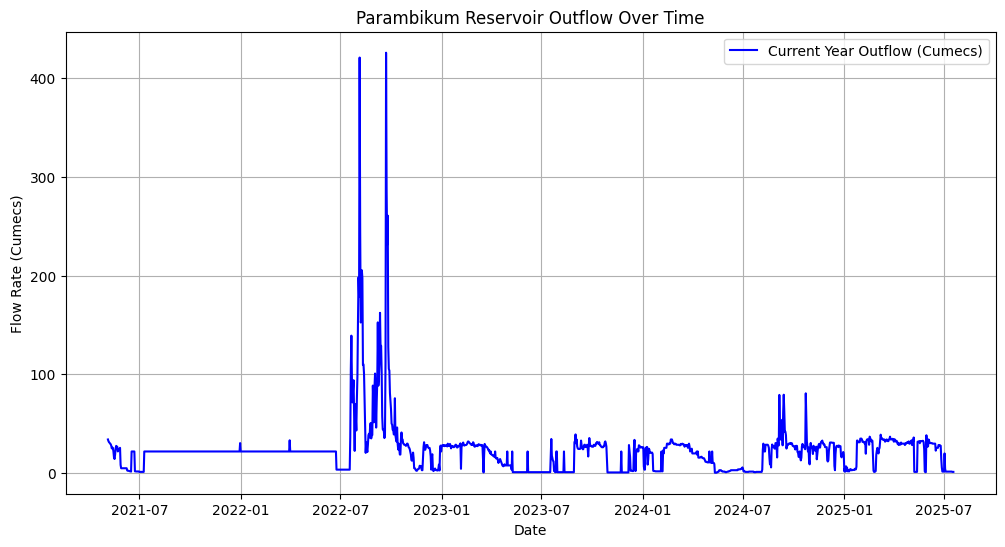

In [ ]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # Read the CSV file
# file_path = '/content/drive/MyDrive/cos_it_flows/Historical/input/Processed data/Reservoir_data/TN_RES/Parambikulam_Reservoirs_Consolidated.csv'
# data = pd.read_csv(file_path)

# # Convert the 'Date' column to datetime format, specifying the correct format
# data['date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

# # Convert flow columns to numeric, coercing errors to NaN
# data['Current Year Outflow (Cumecs)'] = pd.to_numeric(data['Current Year Outflow (Cumecs)'], errors='coerce')
# # data['Spillway_Release(m^3/s)'] = pd.to_numeric(data['Spillway_Release(m^3/s)'], errors='coerce')


# # Create the plot
# plt.figure(figsize=(12, 6))

# # Plot Total Outflow
# plt.plot(data['date'], data['Current Year Outflow (Cumecs)'], label='Current Year Outflow (Cumecs)', color='blue')

# # Plot Spillway Release as a dotted line
# # plt.plot(data['date'], data['Spillway_Release(m^3/s)'], label='Spillway Release (m³/s)', color='orange', linestyle='dotted')

# # Adding titles and labels
# plt.title('Parambikum Reservoir Outflow Over Time')
# plt.xlabel('Date')
# plt.ylabel('Flow Rate (Cumecs)')
# plt.legend()
# plt.grid()

# # Show the plot
# plt.show()

# import pandas as pd
# import matplotlib.pyplot as plt

# # Read the CSV file
# file_path = '/content/drive/MyDrive/cos_it_flows/Historical/input/Processed data/Reservoir_data/TN_RES/Sholayar_Reservoirs_Consolidated.csv'
# data = pd.read_csv(file_path)

# # Convert the 'Date' column to datetime format, specifying the correct format
# data['date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

# # Convert flow columns to numeric, coercing errors to NaN
# data['Current Year Outflow(CuSecs)'] = pd.to_numeric(data['Current Year Outflow(CuSecs)'], errors='coerce')
# # data['Spillway_Release(m^3/s)'] = pd.to_numeric(data['Spillway_Release(m^3/s)'], errors='coerce')


# # Create the plot
# plt.figure(figsize=(12, 6))

# # Plot Total Outflow
# plt.plot(data['date'], data['Current Year Outflow(CuSecs)'], label='Current Year Outflow (CuSecs)', color='blue')

# # Plot Spillway Release as a dotted line
# # plt.plot(data['date'], data['Spillway_Release(m^3/s)'], label='Spillway Release (m³/s)', color='orange', linestyle='dotted')

# # Adding titles and labels
# plt.title('Sholayar Reservoir Outflow Over Time')
# plt.xlabel('Date')
# plt.ylabel('Flow Rate (CuSecs)')
# plt.legend()
# plt.grid()

# # Show the plot
# plt.show()


# import pandas as pd
# import matplotlib.pyplot as plt

# # Read the CSV file
# file_path = '/content/drive/MyDrive/cos_it_flows/Historical/input/Processed data/Reservoir_data/TN_RES/Periyar_Reservoirs_Consolidated.csv'
# data = pd.read_csv(file_path)

# # Convert the 'Date' column to datetime format, specifying the correct format
# data['date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

# # Convert flow columns to numeric, coercing errors to NaN
# data['Current Year Outflow(CuSecs)'] = pd.to_numeric(data['Current Year Outflow(CuSecs)'], errors='coerce')
# # data['Spillway_Release(m^3/s)'] = pd.to_numeric(data['Spillway_Release(m^3/s)'], errors='coerce')


# # Create the plot
# plt.figure(figsize=(12, 6))

# # Plot Total Outflow
# plt.plot(data['date'], data['Current Year Outflow(CuSecs)'], label='Current Year Outflow (CuSecs)', color='blue')

# # Plot Spillway Release as a dotted line
# # plt.plot(data['date'], data['Spillway_Release(m^3/s)'], label='Spillway Release (m³/s)', color='orange', linestyle='dotted')

# # Adding titles and labels
# plt.title('Periyar Reservoir Outflow Over Time')
# plt.xlabel('Date')
# plt.ylabel('Flow Rate (CuSecs)')
# plt.legend()
# plt.grid()

# # Show the plot
# plt.show()
